# E-commerce sales analysis

2024 and 2025 orders. Source: Data Career School.

Status: points 1-4 are implemented in scripts/reports. Sections 3 and 4 reproduce and display results; later sections remain an outline.


## 1. Load and validate the three files

Check schemas, types, keys, duplicates, missing values, labels, numeric ranges, date coverage, and join integrity before analysis. Preserve the original files. Record the issue, affected count, action, rationale, and remaining limitations for every cleaning decision. Save any cleaned record-level exports under `data/cleaned/`.

## 2. Define revenue and comparison metrics

Document eligible order statuses, the order revenue formula, discount treatment, shipping treatment, currency, time basis, and missing-price policy before calculating results. Define category order counts, return and cancellation denominators, category AOV, and how orders containing multiple categories are handled.

## 3. Monthly revenue and year-over-year comparison

Revenue uses known-price completed lines; AOV uses only fully priced completed orders. Shipping is excluded. Run the following cells in order to reproduce and display the monthly results. The scripts own calculation logic so notebook and report totals stay consistent. Cleaning and initial metric reports must exist first.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "compare_monthly_revenue.py").is_file():
    raise FileNotFoundError("Run this notebook from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT / "scripts"))
from compare_monthly_revenue import main
main()


Known-price merchandise revenue increased 20.91% from 2024 to 2025. 2025 revenue exceeded the matching 2024 month in 12 of 12 months.
The two highest revenue months in 2024 were November ($99,725.00), December ($86,011.90).
The two highest revenue months in 2025 were November ($127,233.13), June ($90,781.42).
Completed-line price coverage ranged from 97.81% (2025-11) to 99.78% (2024-09). These are record coverage rates, not percentages of revenue captured; unknown selling prices could affect the comparisons.
Both years place November among their two highest revenue months. This suggests a recurring peak, but two years cannot establish a stable seasonal pattern or its cause.
Passed: input hashes, 24 months present, unchanged overall/annual baselines, monthly-to-annual and overall counts, exact money and AOV reconciliation.


In [2]:
monthly = pd.read_csv(ROOT / "reports/monthly_metrics.csv")
yoy = pd.read_csv(ROOT / "reports/monthly_yoy.csv")
coverage = pd.read_csv(ROOT / "reports/monthly_date_coverage.csv")
display(coverage)
display(monthly)
display(yoy)


,month,first_order_utc,last_order_utc,calendar_days,observed_order_days,days_without_recorded_orders
0,2024-01,2024-01-01T09:24:45+00:00,2024-01-31T21:23:07+00:00,31,31,0
1,2024-02,2024-02-01T06:33:23+00:00,2024-02-29T21:43:58+00:00,29,29,0
2,2024-03,2024-03-01T07:39:20+00:00,2024-03-31T20:04:00+00:00,31,31,0
3,2024-04,2024-04-01T13:47:33+00:00,2024-04-30T22:09:57+00:00,30,30,0
4,2024-05,2024-05-01T06:25:30+00:00,2024-05-31T23:30:28+00:00,31,31,0
5,2024-06,2024-06-01T10:53:27+00:00,2024-06-30T20:51:18+00:00,30,30,0
6,2024-07,2024-07-01T06:52:38+00:00,2024-07-31T23:18:11+00:00,31,31,0
7,2024-08,2024-08-01T06:48:50+00:00,2024-08-31T21:57:58+00:00,31,31,0
8,2024-09,2024-09-01T07:59:26+00:00,2024-09-30T22:23:40+00:00,30,30,0
9,2024-10,2024-10-01T06:27:07+00:00,2024-10-31T20:49:35+00:00,31,31,0


,month,all_orders,completed_orders,canceled_orders,returned_orders,cancellation_rate,return_rate,completed_units_sold,known_price_merchandise_revenue_usd,completed_shipping_income_usd,completed_item_lines,completed_known_price_lines,completed_missing_price_lines,completed_missing_price_units,completed_line_price_coverage,completed_orders_with_all_prices,completed_orders_with_missing_prices,completed_order_price_coverage,fully_priced_completed_order_revenue_usd,aov_fully_priced_completed_orders_usd
0,2024-01,287,263,12,12,0.041812,0.041812,559,54107.56,430.90,443,439,4,5,0.990971,259,4,0.984791,54028.59,208.60
1,2024-02,293,278,9,6,0.030717,0.020478,648,62945.69,375.30,508,503,5,7,0.990157,273,5,0.982014,61820.77,226.45
2,2024-03,324,296,14,14,0.043210,0.043210,664,70885.83,417.00,521,517,4,5,0.992322,292,4,0.986486,70589.87,241.75
3,2024-04,317,292,9,16,0.028391,0.050473,588,64177.27,465.65,485,479,6,8,0.987629,286,6,0.979452,63331.33,221.44
4,2024-05,338,307,19,12,0.056213,0.035503,667,72246.90,403.10,540,535,5,6,0.990741,303,4,0.986971,71558.96,236.17
5,2024-06,327,300,10,17,0.030581,0.051988,612,66600.43,403.10,497,493,4,5,0.991952,296,4,0.986667,65419.54,221.01
6,2024-07,350,322,13,15,0.037143,0.042857,676,76264.13,423.95,543,536,7,9,0.987109,315,7,0.978261,75275.20,238.97
7,2024-08,318,291,12,15,0.037736,0.047170,573,61490.69,458.70,470,463,7,12,0.985106,284,7,0.975945,60115.82,211.68
8,2024-09,288,255,12,21,0.041667,0.072917,548,60028.03,396.15,454,453,1,1,0.997797,254,1,0.996078,59989.04,236.18
9,2024-10,332,308,13,11,0.039157,0.033133,647,66652.90,465.65,524,517,7,7,0.986641,301,7,0.977273,66066.96,219.49


,month_number,month,revenue_2024,revenue_2025,revenue_yoy_change,revenue_yoy_rate,completed_orders_2024,completed_orders_2025,completed_orders_yoy_change,completed_orders_yoy_rate,aov_2024,aov_2025,aov_yoy_change,aov_yoy_rate
0,1,Jan,54107.56,72297.91,18190.35,0.336189,263,303,40,0.152091,208.60,238.61,30.01,0.143864
1,2,Feb,62945.69,69676.90,6731.21,0.106937,278,305,27,0.097122,226.45,228.10,1.65,0.007286
2,3,Mar,70885.83,77653.21,6767.38,0.095469,296,352,56,0.189189,241.75,224.43,-17.32,-0.071644
3,4,Apr,64177.27,79149.13,14971.86,0.233289,292,372,80,0.273973,221.44,212.98,-8.46,-0.038204
4,5,May,72246.90,81840.61,9593.71,0.132791,307,367,60,0.195440,236.17,224.56,-11.61,-0.049160
5,6,Jun,66600.43,90781.42,24180.99,0.363076,300,373,73,0.243333,221.01,246.38,25.37,0.114791
6,7,Jul,76264.13,82258.71,5994.58,0.078603,322,343,21,0.065217,238.97,243.68,4.71,0.019710
7,8,Aug,61490.69,89058.38,27567.69,0.448323,291,371,80,0.274914,211.68,240.97,29.29,0.138369
8,9,Sep,60028.03,74622.57,14594.54,0.243129,255,336,81,0.317647,236.18,223.27,-12.91,-0.054662
9,10,Oct,66652.90,81635.16,14982.26,0.224780,308,379,71,0.230519,219.49,216.50,-2.99,-0.013622


# Monthly revenue comparison: 2024 and 2025

## Scope and date coverage

Uses the definitions in [metrics.md](metrics.md). Revenue includes known-price completed lines; AOV uses only completed orders with every line priced. Shipping is separate. Missing prices are not estimated. All periods use UTC order dates and final recorded status.

All 24 expected months are present. First order: 2024-01-01T09:24:45+00:00; last order: 2025-12-31T23:23:29+00:00. There are 0 calendar days without recorded orders. See monthly_date_coverage.csv for month boundaries and observed day counts. Recorded transactions across the period do not independently prove the source extract is complete. February has 29 days in 2024 and 28 in 2025; comparisons use calendar-month totals, not daily averages.

## Observations

- Known-price merchandise revenue increased 20.91% from 2024 to 2025. 2025 revenue exceeded the matching 2024 month in 12 of 12 months.
- The two highest revenue months in 2024 were November ($99,725.00), December ($86,011.90).
- The two highest revenue months in 2025 were November ($127,233.13), June ($90,781.42).
- Completed-line price coverage ranged from 97.81% (2025-11) to 99.78% (2024-09). These are record coverage rates, not percentages of revenue captured; unknown selling prices could affect the comparisons.
- Both years place November among their two highest revenue months. This suggests a recurring peak, but two years cannot establish a stable seasonal pattern or its cause.



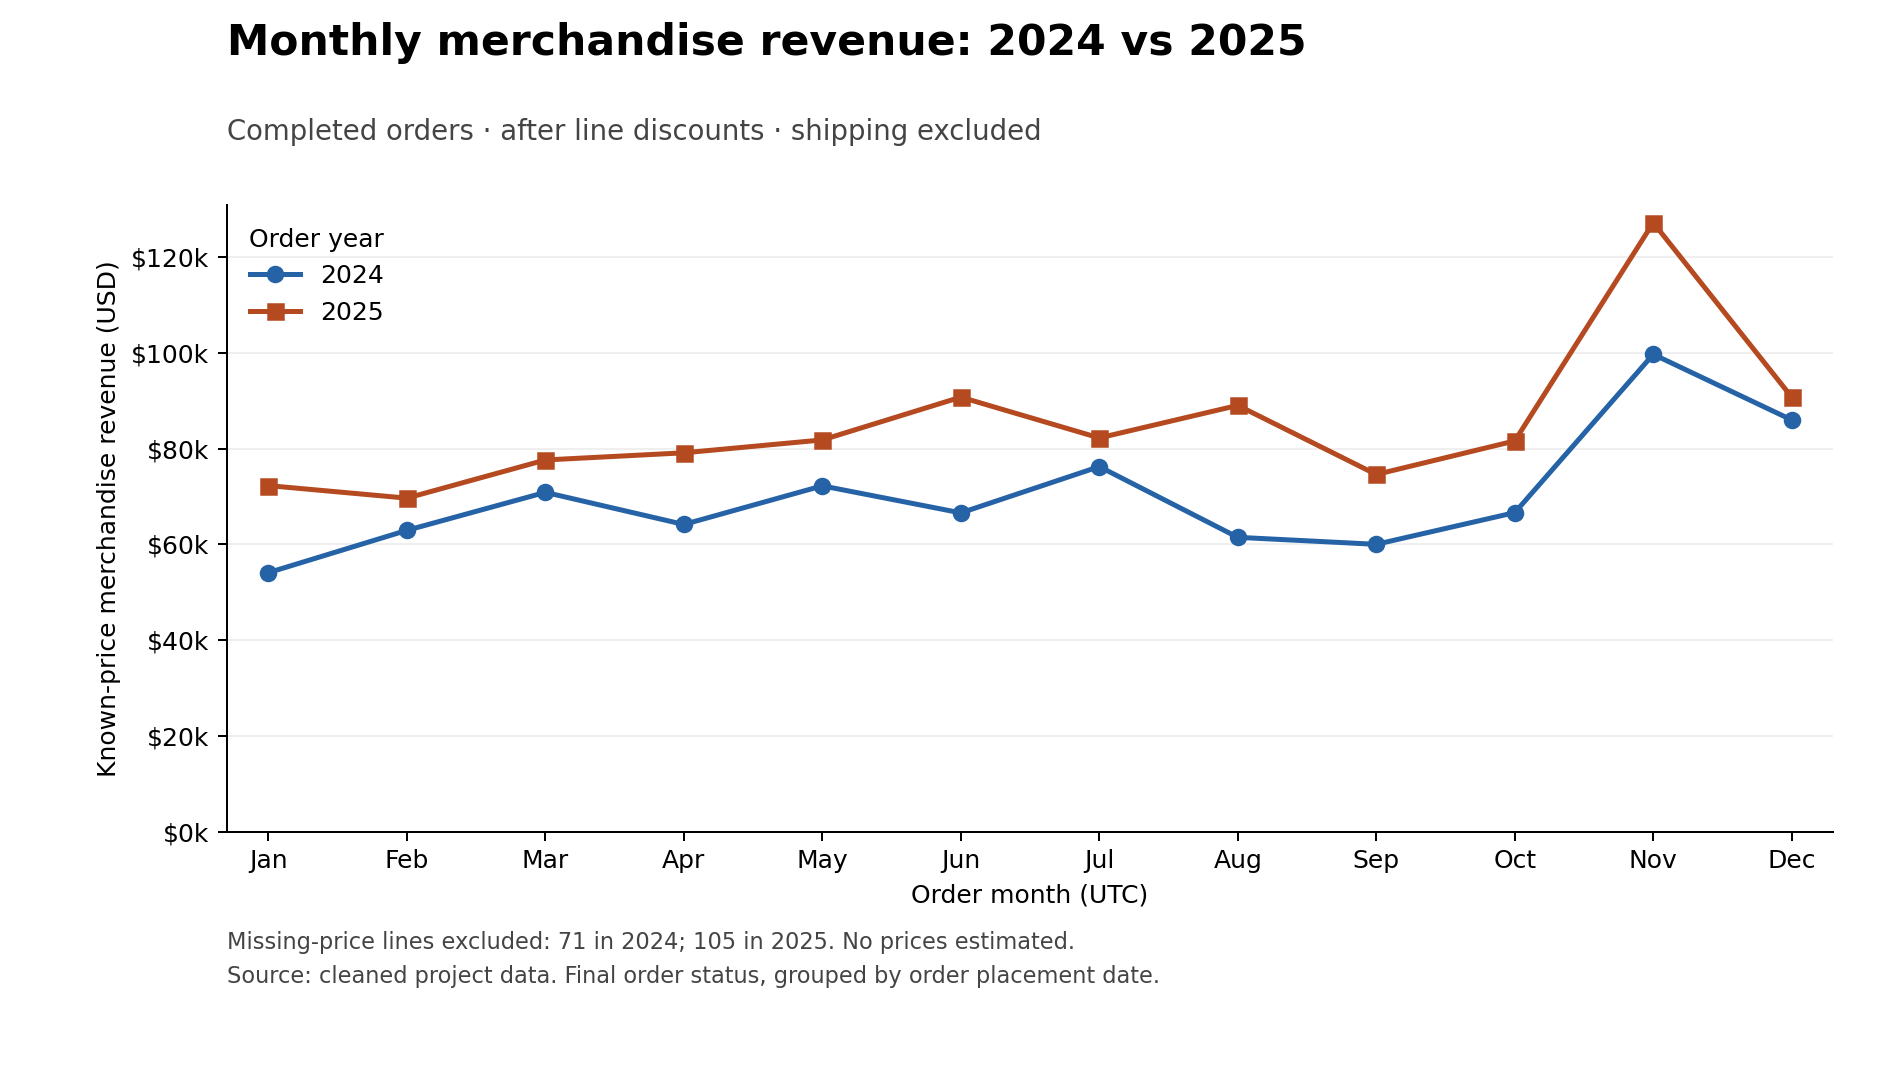

In [3]:
display(Markdown((ROOT / "reports/monthly_revenue.md").read_text(encoding="utf-8").split("## Revenue comparison")[0]))
display(Image(filename=str(ROOT / "reports/figures/monthly_revenue.png")))


## 4. Category revenue, product quantities, and category mix

Compare category revenue across years, rank the top 10 products by combined completed units, and compare monthly revenue composition in aligned 2024/2025 panels. Revenue includes known-price completed lines only; quantity includes completed units with missing prices. Run section 3 first for notebook setup and monthly baselines.


In [4]:
from analyze_categories import main as analyze_categories
analyze_categories()


Furniture generated the most combined known-price revenue: $318,593.13 (17.15% of 2024–2025 revenue).
Nordic Ornament Set (ID 1078) ranked first by completed quantity: 355 units.
Outdoor had the largest absolute annual revenue-share change: 13.84% in 2024 to 12.56% in 2025 (-1.28 percentage points).
Outdoor reached its highest monthly revenue share in June 2024 (34.56%) and June 2025 (26.15%). These are composition peaks, not necessarily peak dollar sales.
Decor reached its highest monthly revenue share in November 2024 (23.84%) and December 2025 (25.87%). These are composition peaks, not necessarily peak dollar sales.
Passed: cleaned hashes and baseline metrics; joins preserve item rows; category, product, annual and all 24 monthly revenues, units and missing-price counts reconcile; category totals reconcile across views; monthly shares sum to 100%.


In [5]:
category_annual = pd.read_csv(ROOT / "reports/category_revenue_annual.csv")
product_rankings = pd.read_csv(ROOT / "reports/product_rankings.csv", dtype={"product_id": str})
category_mix = pd.read_csv(ROOT / "reports/monthly_category_mix.csv")
display(category_annual)
display(product_rankings.head(10))
display(category_mix)


,year,category,completed_units,completed_lines,priced_lines,missing_price_units,missing_price_lines,line_price_coverage,revenue_share,known_price_revenue_usd
0,2024,Bath,931,751,744,9,7,0.990679,0.059306,49884.59
1,2024,Bedding,1080,851,843,12,8,0.990599,0.146194,122968.88
2,2024,Decor,1694,1311,1297,18,14,0.989321,0.149577,125814.80
3,2024,Furniture,411,411,406,5,5,0.987835,0.168284,141549.39
4,2024,Kitchen,1666,1330,1314,19,16,0.987970,0.145318,122232.49
5,2024,Lighting,692,546,540,9,6,0.989011,0.125100,105226.04
6,2024,Outdoor,777,642,638,5,4,0.993769,0.138399,116412.15
7,2024,Storage,964,761,750,16,11,0.985545,0.067823,57047.99
8,2025,Bath,1063,837,829,9,8,0.990442,0.057221,58193.09
9,2025,Bedding,1174,921,910,15,11,0.988056,0.138992,141352.38


,rank,product_id,product_name,category,completed_units,completed_lines,priced_lines,missing_price_units,missing_price_lines,line_price_coverage,known_price_revenue_usd
0,1,1078,Nordic Ornament Set,Decor,355,262,260,2,2,0.992366,30347.40
1,2,1072,Coastal Picture Frame Set,Decor,310,250,247,4,3,0.988000,43702.80
2,3,1075,Matte Black Throw Pillow,Decor,308,240,237,3,3,0.987500,15346.11
3,4,1073,Rattan Candle Trio,Decor,307,246,246,0,0,1.000000,21077.64
4,5,1071,Oak Vase,Decor,306,240,238,4,2,0.991667,3025.07
5,6,1074,Nordic Wall Art Print,Decor,305,240,235,8,5,0.979167,5905.02
6,7,1079,Linen Faux Plant,Decor,299,238,235,5,3,0.987395,18073.65
7,8,1076,Modern Wreath,Decor,296,227,224,6,3,0.986784,40183.10
8,9,1080,Classic Garland,Decor,288,232,230,2,2,0.991379,38397.95
9,10,1077,Classic Table Runner,Decor,282,219,216,4,3,0.986301,7139.59


,month,category,year,month_number,completed_units,completed_lines,priced_lines,missing_price_units,missing_price_lines,line_price_coverage,revenue_share,known_price_revenue_usd
0,2024-01,Furniture,2024,1,23,23,23,0,0,1.000000,0.122419,6623.77
1,2024-01,Kitchen,2024,1,125,99,98,1,1,0.989899,0.163293,8835.36
2,2024-01,Decor,2024,1,105,89,89,0,0,1.000000,0.151654,8205.65
3,2024-01,Bedding,2024,1,88,66,65,1,1,0.984848,0.199178,10777.03
4,2024-01,Outdoor,2024,1,11,11,11,0,0,1.000000,0.030955,1674.89
...,...,...,...,...,...,...,...,...,...,...,...,...
187,2025-12,Bedding,2025,12,133,99,98,2,1,0.989899,0.168404,15287.34
188,2025-12,Outdoor,2025,12,21,18,18,0,0,1.000000,0.039644,3598.77
189,2025-12,Lighting,2025,12,61,55,55,0,0,1.000000,0.113154,10271.86
190,2025-12,Storage,2025,12,84,67,65,2,2,0.970149,0.058498,5310.30


# Category and product analysis: 2024–2025

## Definitions and scope

Uses [the agreed revenue definition](metrics.md): known-price lines from completed orders, quantity × historical unit price − line discount, excluding shipping. No prices are estimated. Revenue is calculated in integer cents and grouped by UTC order placement date and final status. Canceled and returned orders are excluded. Products and categories are joined by product ID.

Category share = category known-price revenue ÷ total known-price revenue for the same period. Monthly shares use each month’s total; annual shares use each year’s total. Missing prices may affect the revenue ranking and mix. Line coverage is record coverage, not the percentage of dollar revenue captured. Product quantities include completed units even when their selling price is missing. Rankings use product ID to keep names distinct; ties are ordered by numeric product ID, with exactly ten products shown.

## Observations

- Furniture generated the most combined known-price revenue: $318,593.13 (17.15% of 2024–2025 revenue).
- Nordic Ornament Set (ID 1078) ranked first by completed quantity: 355 units.
- Outdoor had the largest absolute annual revenue-share change: 13.84% in 2024 to 12.56% in 2025 (-1.28 percentage points).
- Outdoor reached its highest monthly revenue share in June 2024 (34.56%) and June 2025 (26.15%). These are composition peaks, not necessarily peak dollar sales.
- Decor reached its highest monthly revenue share in November 2024 (23.84%) and December 2025 (25.87%). These are composition peaks, not necessarily peak dollar sales.



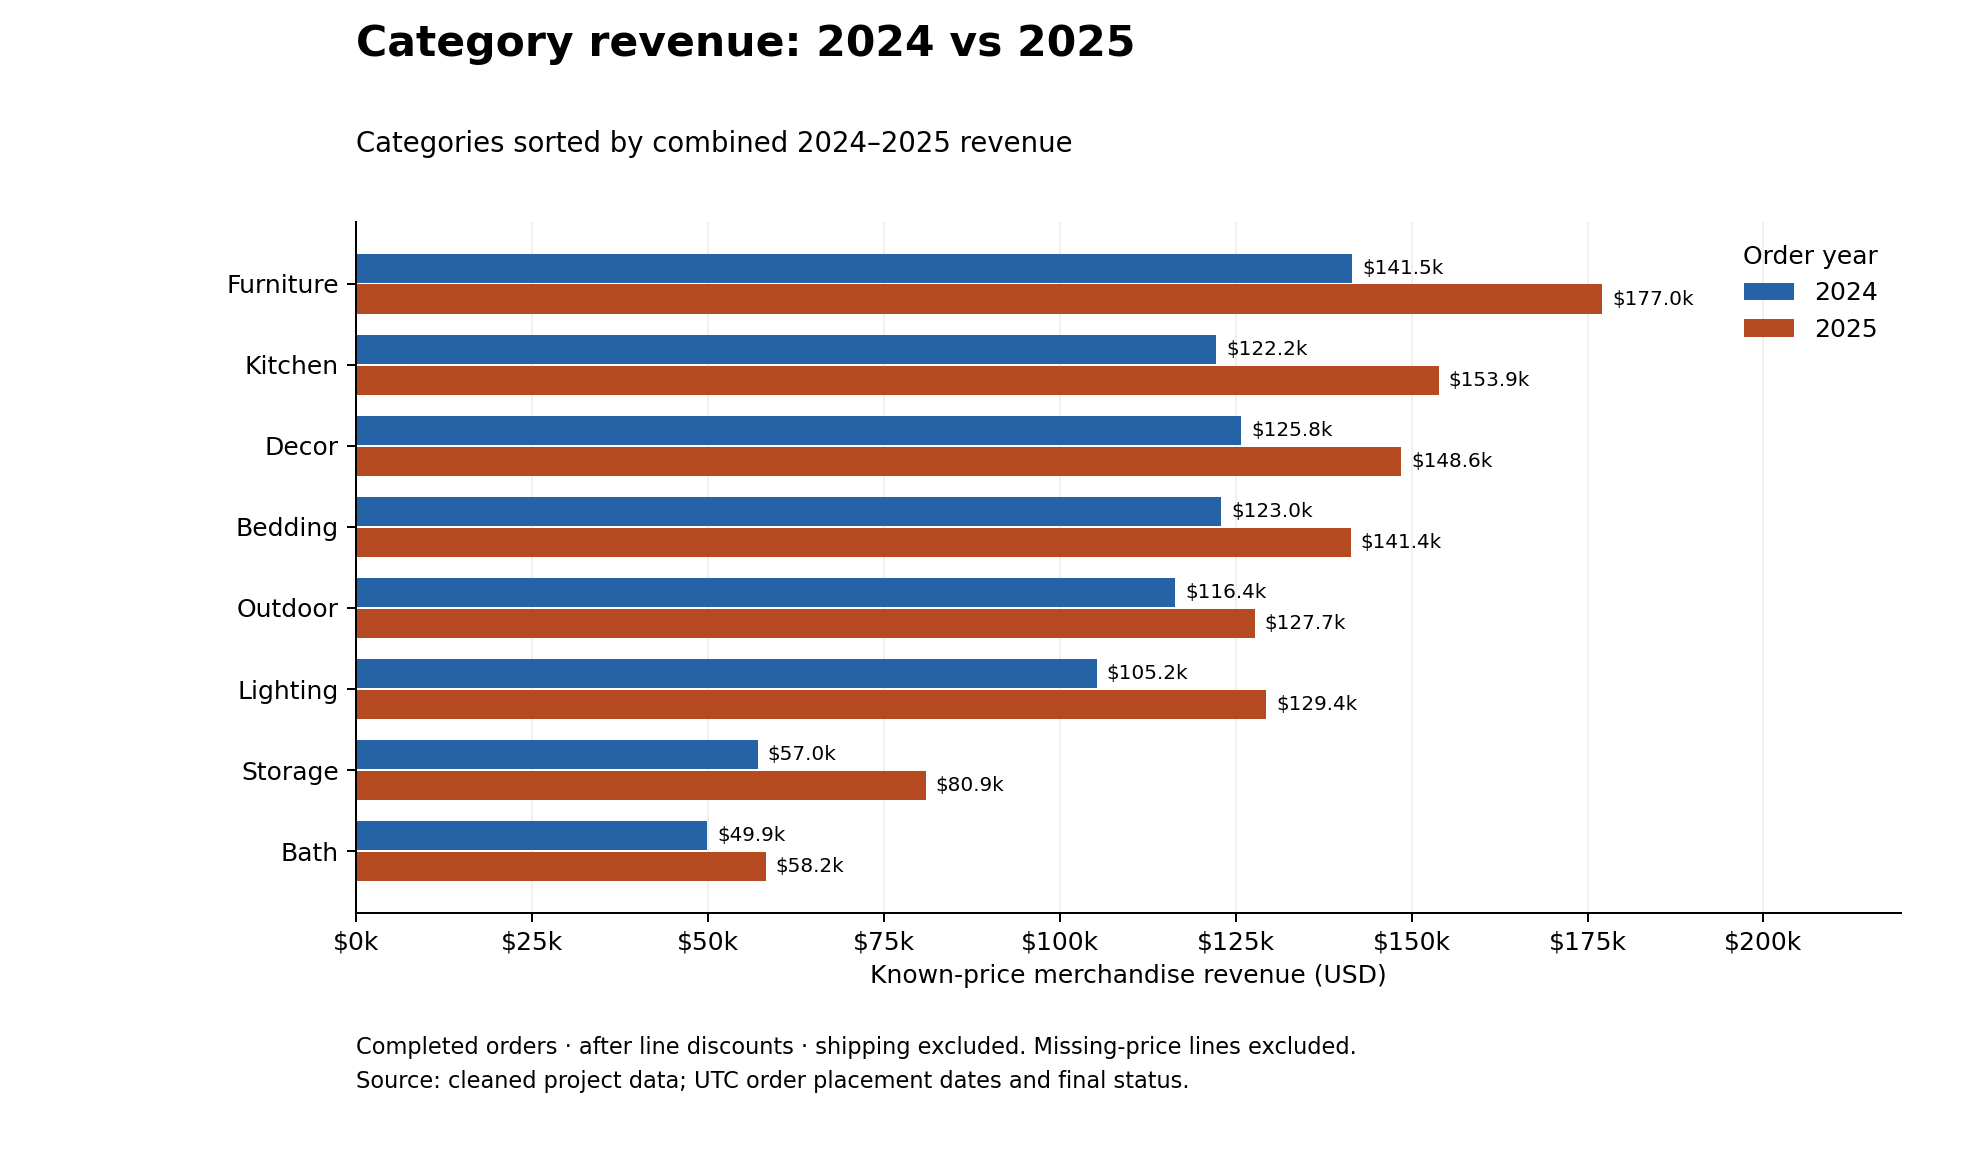

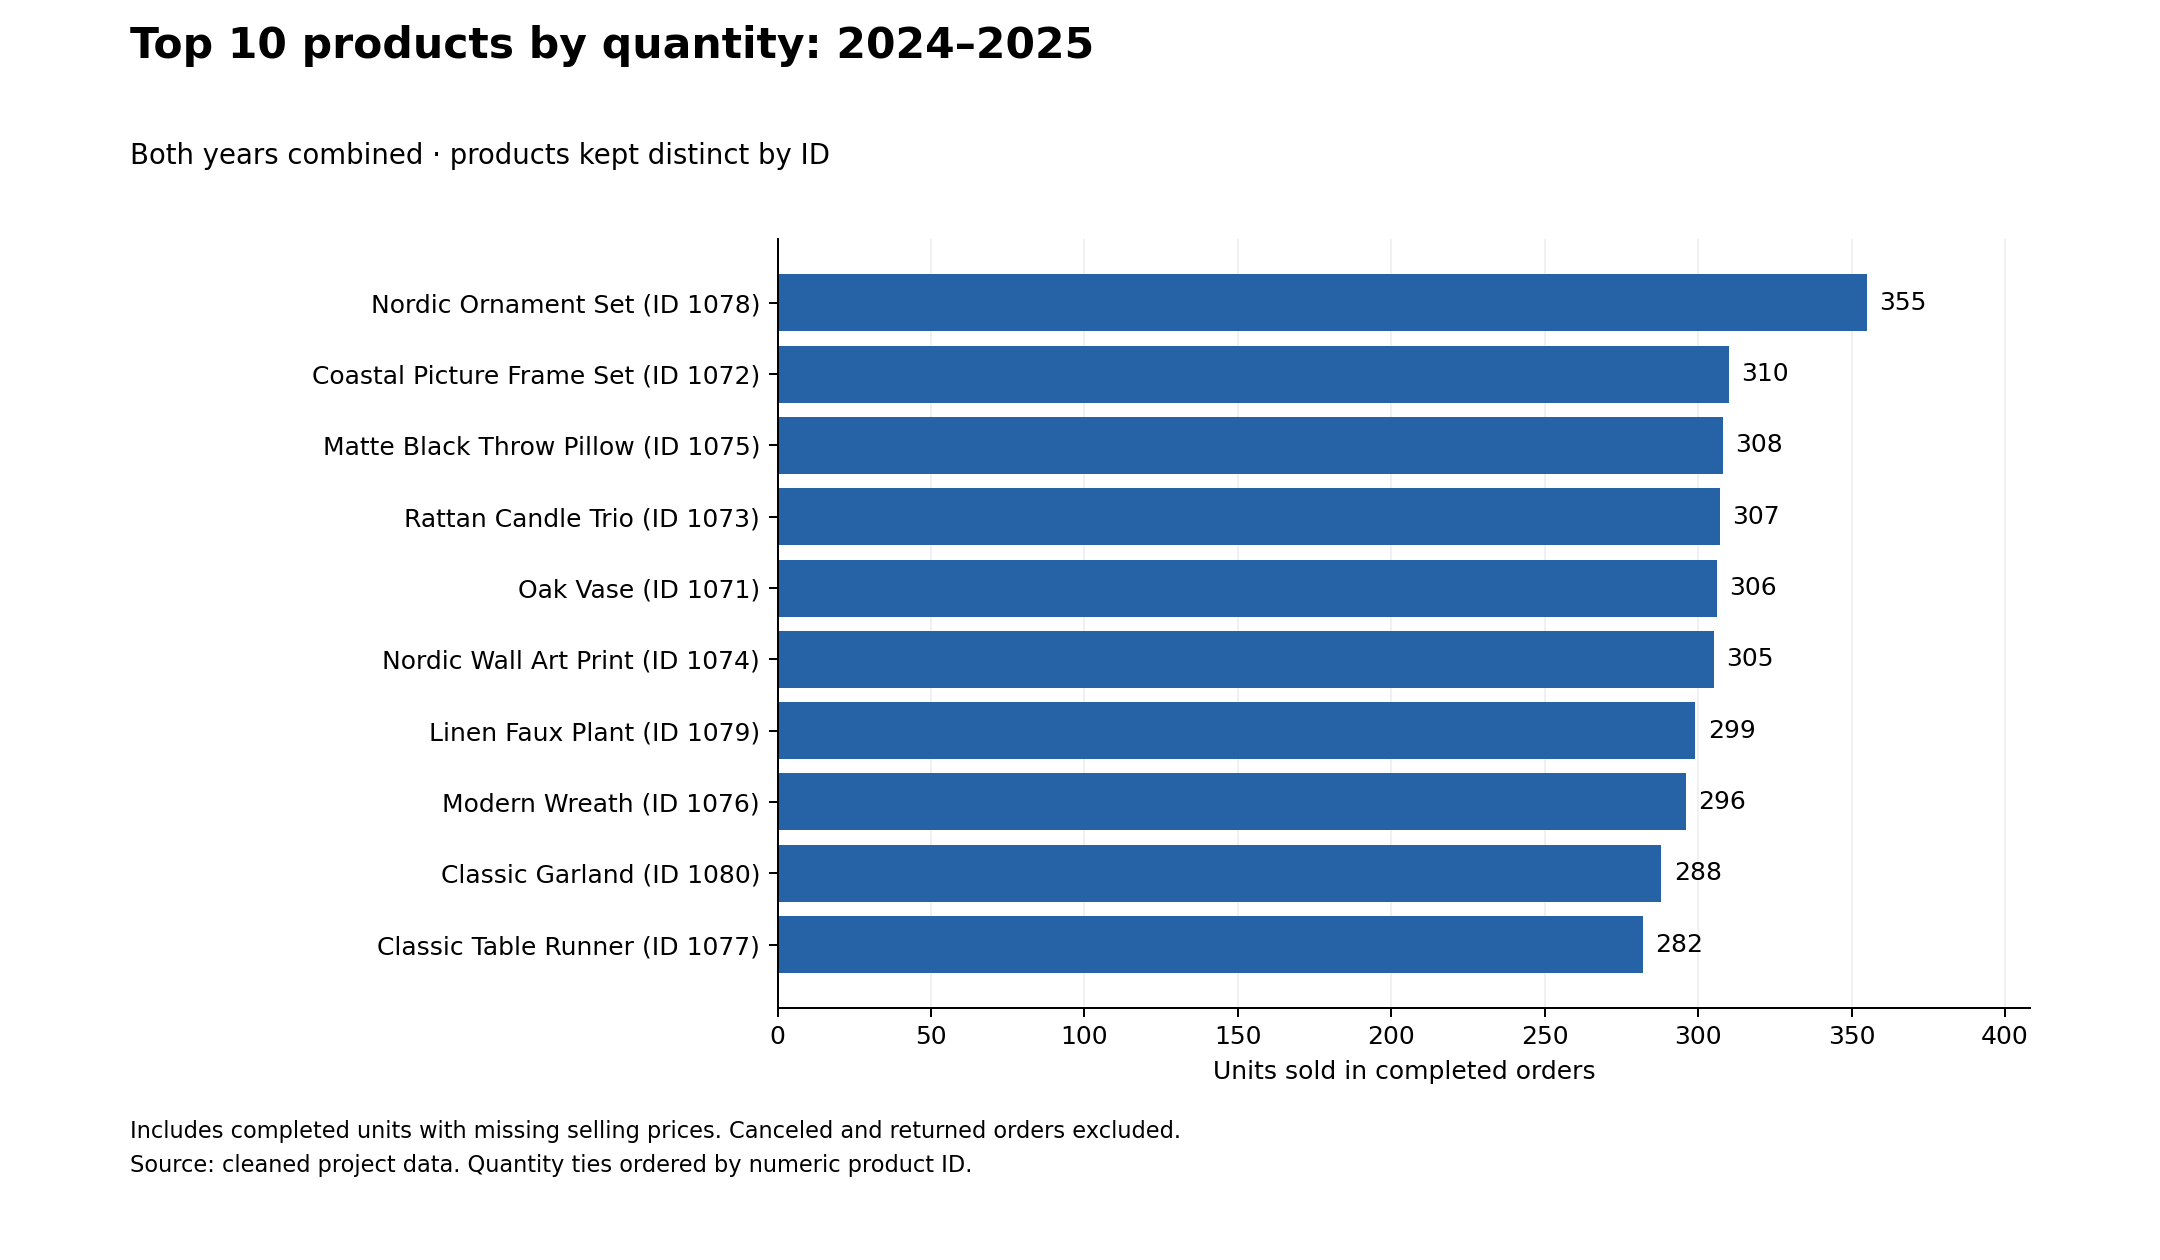

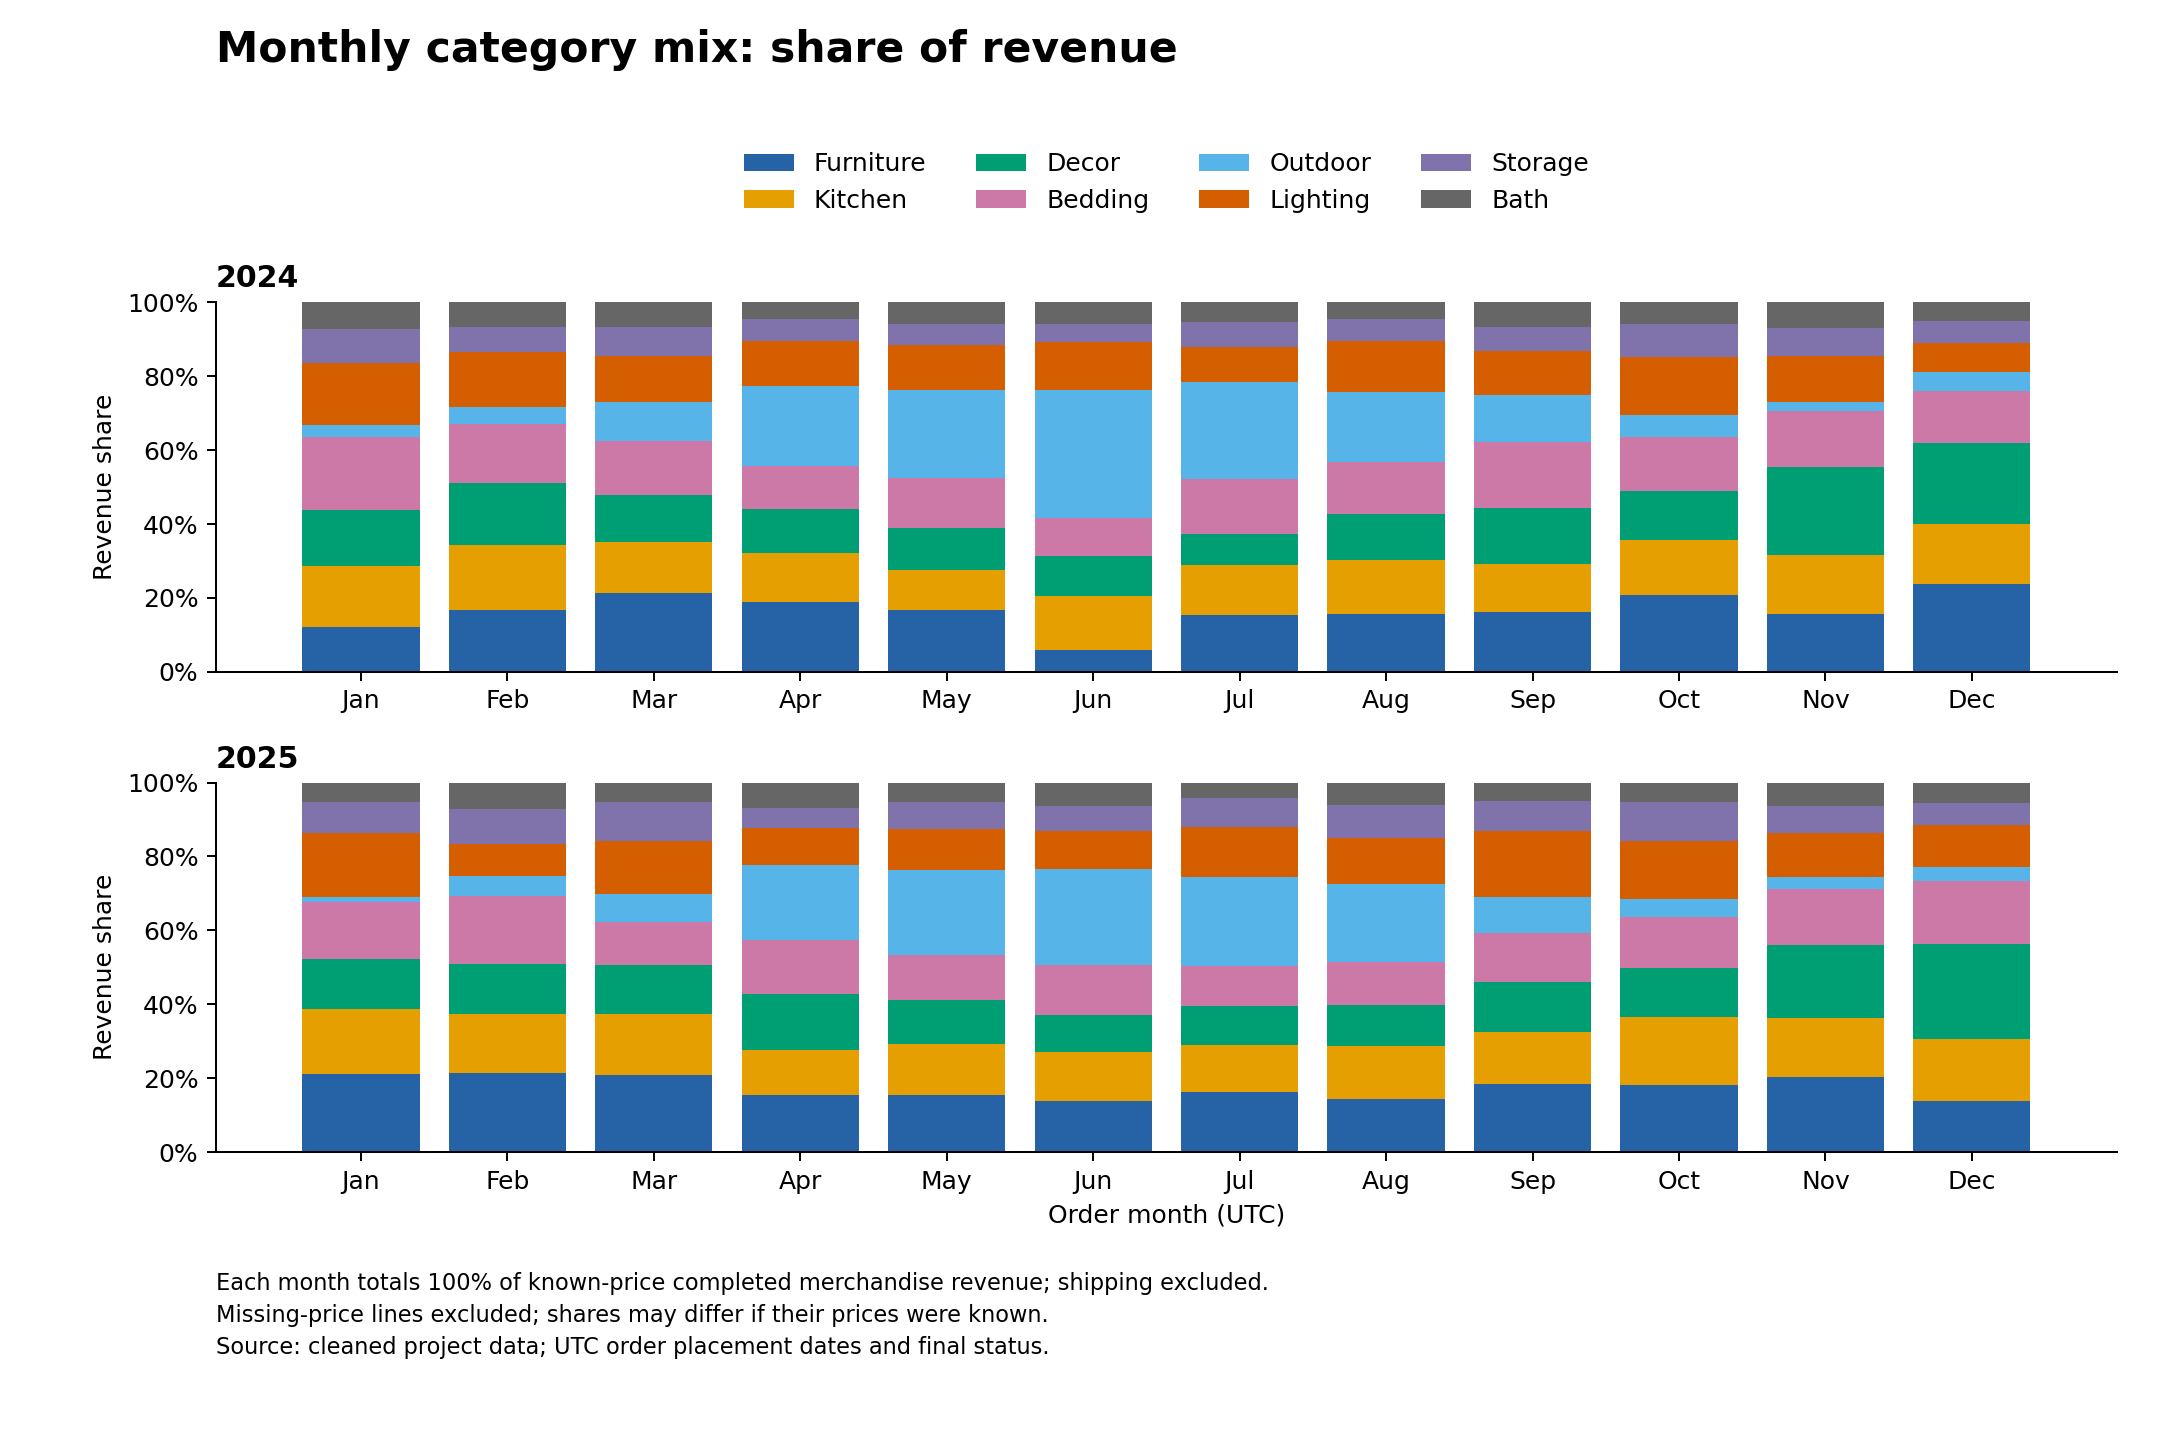

In [6]:
display(Markdown((ROOT / "reports/category_analysis.md").read_text(encoding="utf-8").split("## Category revenue by year")[0]))
for figure in ("category_revenue", "top_products", "monthly_category_mix"):
    display(Image(filename=str(ROOT / f"reports/figures/{figure}.png")))


## 5. Category return rates, cancellation rates, and AOV

Report distinct-order denominators and sample sizes alongside percentages. Use the definitions established in section 2.

## 6. Charts and reconciliation

Produce at least three labeled charts with periods, units, and relevant populations. Save figures under `reports/figures/`. Reconcile order, monthly, category, and annual totals before drawing conclusions.

## 7. Findings and recommendations

Write exactly three evidence-based findings and two recommendations for the following year's plan in `reports/summary.md`. Summarize the verified results in the README.